# Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import json

# Import parameters

In [2]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

def calculate_variables(params):
    array_length = params["array"]["length"] #transducer array length
    frequency = params["wave"]["frequency"] #hz
    c = params["wave"]["c"] #speed of sound in m/s
    sampling_rate = params["wave"]["sampling_rate"] #1/s = 16 * frequency
    total_depth = params["simulation"]["total_depth"] #total depth in m
    pitch = params["array"]["pitch"] #pitch in m
    
    step_size = 1 / sampling_rate #cuz frequency = 1 / T 
    samples = int(sampling_rate * (total_depth / c)) #sampling rate 1/s * total depth m / (m/s) = samples - samples needed to cover the total depth
    total_depth_sample = (total_depth / 2) / samples #total depth in m / number of samples = depth per sample
    
    pos = np.linspace(start=0, stop=array_length, num=array_length, dtype=int) #array position sampling
    time = np.linspace(start=0, stop=step_size * samples, num=samples) #time sampling
    
    params["simulation"]["step_size"] = step_size #step size in s
    params["simulation"]["samples"] = samples 
    params["simulation"]["total_depth_sample"] = total_depth_sample #depth per sample in m
    params["simulation"]["maximal_acquisition_depth"] = c * (step_size * samples) / 2 #maximal acquisition depth in m
    params["simulation"]["lateral_step"] = (array_length * pitch) * (1 / params['simulation']['lateral_resolution'])
    
    print("Aperture: ", params["array"]["aperture"])
    print("Samples: ", samples)
    print("Total depth samples: ", total_depth_sample)
    print("Step size: ", step_size, "s")
    print("Maximal acquisition depth:", params["simulation"]["maximal_acquisition_depth"], "m")
    print("Lateral step: ", params["simulation"]["lateral_step"], "m")
    
    return params, pos, time

In [3]:
parameters = load_parameters("./parameters.json")
params, pos, time = calculate_variables(parameters)

Aperture:  0.8
Samples:  3200
Total depth samples:  3.125e-06
Step size:  4.166666666666667e-09 s
Maximal acquisition depth: 0.01 m
Lateral step:  6.25e-06 m


# NSI

In [4]:
def generate_apodization(array_length, index, offset=0, mirror=False):
    if index >= 1 and index < array_length / 2:
        if mirror:
            return -1 + offset
        else:
            return 1 + offset
    elif index>=array_length/2 and index < array_length:
        if mirror:
            return 1 + offset
        else:
            return -1 + offset

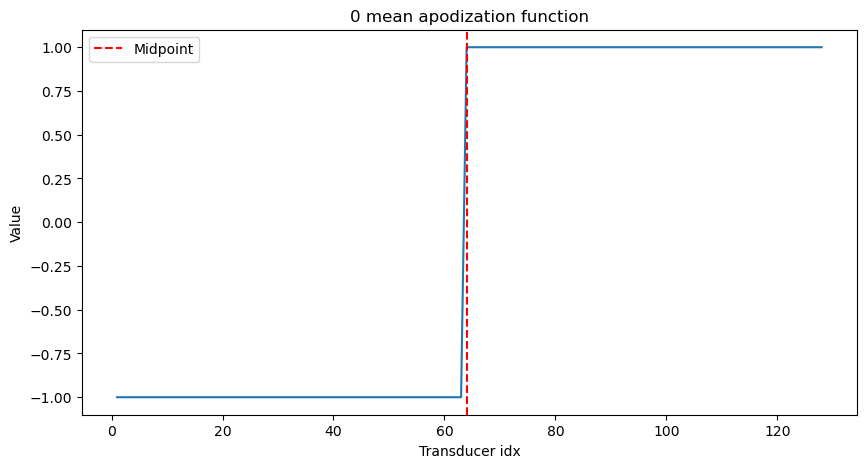

In [9]:
import numpy as np
import matplotlib.pyplot as plt

y = np.array([generate_apodization(params["array"]["length"], i, offset=0, mirror=True) for i in range(params["array"]["length"])])

plt.figure(figsize=(10, 5))
plt.plot(pos, y)
plt.title('0 mean apodization function')
plt.xlabel('Transducer idx')
plt.ylabel('Value')
plt.axvline(x=params["array"]["length"]/2, color='r', linestyle='--', label='Midpoint')
plt.legend()
plt.show()